# Fixed discount factor for firms: A shock and demand shock

In the other time-to-produce notebooks firms discount production over the lag $\tau$ at the
**policy rate**, $\beta_t = 1/(1+i_t)$. That hands monetary policy a first-order lever on
productivity — cutting rates raises $\text{tprod} = \beta^\tau c\,(\tau+N)$ — with nothing
to offset it, so the planner cuts to the lower bound and never comes back.

Here firms instead discount at a **fixed** $\beta_f = 1/(1+\rho)$, independent of policy.
Tested variants and what they did:

| firm discount factor | escalation |
|---|---|
| nominal $1/(1+i_t)$ | corners at $0.00$, never settles |
| sticky partial adjustment, $\omega<1$ | never settles (full long-run pass-through) |
| real rate $i_t-\pi_{t+1}$ | corners at $0.00$, never settles |
| household SDF $\beta(C_{t+1}/C_t)^{-\gamma}$ | corners at $0.05$, never settles |
| **fixed $\beta_f$ (this notebook)** | **settles** |

Fixing $\beta_f$ is the only one that works, because it removes the lever rather than
changing its sign.

Both shocks are run below: a TFP shock and a demand shock, each under the gap objective
$\sum_t x_t^2$ and the planner's utility objective.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize

/Users/samuelzhao/anaconda3/lib/python3.10/site-packages/pandas/core/arrays/masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


## 1. Calibration

In [2]:
INVENTORY_TO_COGS_SCALING = 36.5
data = pd.read_csv('APP_data_usa_goods.csv', index_col=0, parse_dates=True)
data_tau = (data['invtCogsRatio'] * INVENTORY_TO_COGS_SCALING / (30 * 0.1))

beta = 1 / (1.0 + 0.01)
beta1 = 1 / (1.0 + 0.01 * np.exp(30 / (INVENTORY_TO_COGS_SCALING * 0.9)))
beta_hh = beta
rho = 1 / beta_hh - 1

gamma = 2.0                      # relative risk aversion / IS slope
eta = 2.0                        # inverse Frisch elasticity
sigma = 5                        # CES elasticity across firms
PHI_YA = (1 + eta) / (gamma + eta)

# Competitive steady state: no markup enters the allocation in this model, so
# MRS = MPL = 1 at N = C = A = 1 and the labour weight is simply chi = 1.
# (Under fixed wages the labour wedge is (gamma+eta)*x_t, which is zero in steady state.)
chi = 1.0

BETA_FIRM = 1.0 / (1.0 + rho)    # <-- FIXED firm discount factor, independent of policy

print(f'gamma={gamma}, eta={eta}, phi_ya={PHI_YA:.4f}, chi={chi}')
print(f'rho={rho:.6f}   BETA_FIRM={BETA_FIRM:.6f}  (constant)')

gamma=2.0, eta=2.0, phi_ya=0.7500, chi=1.0
rho=0.010000   BETA_FIRM=0.990099  (constant)


/var/folders/26/bmvk0hrd5xbgcvl_s6s42rf80000gn/T/ipykernel_57114/51462618.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  data = pd.read_csv('APP_data_usa_goods.csv', index_col=0, parse_dates=True)


In [3]:
tau_diff = np.zeros(1000)
for i, c in enumerate(np.linspace(0, 0.99, 1000)):
    if beta * c <= 1e-10:
        tau_diff[i] = np.inf
        continue
    N = -(data_tau) - 1/np.log(beta * c)
    t1 = -1/np.log(beta * c) - N;  t1[t1 < 0] = 0
    t2 = -1/np.log(beta1 * c) - N; t2[t2 < 0] = 0
    tau_diff[i] = np.mean(np.abs(t1 - t2))
optimal_c_value = np.linspace(0, 0.99, 1000)[np.argmin(np.abs(tau_diff - 1))]

N = -data_tau - 1/np.log(beta * optimal_c_value)
tau = -1/np.log(beta * optimal_c_value) - N
tau[tau < 0] = 0
tf, tc = np.floor(tau), np.ceil(tau)
pc = (beta * optimal_c_value)**tc * (tc + N)
pf = (beta * optimal_c_value)**tf * (tf + N)
tau[(pc - pf) > 0] = tc[(pc - pf) > 0]
tau[(pc - pf) < 0] = tf[(pc - pf) < 0]
tau[tau < 0] = 0

tvals = tau.astype(int).to_numpy()
N_array = np.array(N)
print(f'optimal c = {optimal_c_value:.7f}   mean tau = {tau.mean():.4f}')

optimal c = 0.9018018   mean tau = 2.8885


In [4]:
def generate_pattern_array_with_extra_rows(tau):
    """Staggering matrix: which firms have re-optimised by period t (shock factor 0.97)."""
    tau = np.asarray(tau)
    n = len(tau) + int(np.min(tau))
    m = int(np.max(tau)) + int(np.min(tau))
    missing_count = len(set(range(int(max(tau)) + 1)) - set(tau))
    A = np.ones((m + 2, n + missing_count), dtype=float)
    count = 0
    for i in range(1, m + 2):
        firms = tau[tau == i - 1]
        for j in range(len(firms)):
            A[i, n - i - j - count] = 0.97
        if len(firms) > 1:
            count += len(firms) - 1
    A_ext = np.vstack([A, np.ones(n + missing_count, dtype=float)])
    return A_ext[:, 0:n - int(np.min(tau))]


A_pattern = generate_pattern_array_with_extra_rows(tau)
print('staggering matrix:', A_pattern.shape)

staggering matrix: (16, 269)


## 2. Model

Same gap-form IS curve as the other notebooks,

$$x_t = x_{t+1} - \tfrac{1}{\gamma}\bigl(i_t - \pi_{t+1} - r^n_t\bigr), \qquad
  r^n_t = \rho - d_t + \gamma\,(y^n_{t+1}-y^n_t), \qquad y^n_t = \varphi_{ya}\,a_t$$

with $y_t = x_t + y^n_t$ and $n_t = y_t - a_t$. The single change is that `tprod` is built
from the constant $\beta_f$:

$$\text{tprod}_i = \beta_f^{\tau_i}\,c\,(\tau_i + N_i)$$

so **$a_t$ no longer depends on the rate path**. Policy still moves output through the
Euler equation; it can no longer move potential.

In [5]:
TPROD = (BETA_FIRM ** tvals) * optimal_c_value * (tvals + N_array)   # fixed, policy-free


def tfp_path(T, shock=True):
    """log TFP deviation from terminal. Independent of policy by construction."""
    prod_shock = np.ones((T, len(tvals)))
    if shock:
        prod_shock[0:15] = A_pattern[1:]
    A = np.sum((prod_shock * TPROD)**(sigma - 1), axis=1)**(1/(sigma - 1))
    return np.log(A) - np.log(A)[-1]


def gap_IS(i_path, a, demand=None, gamma=gamma, eta=eta, beta_hh=beta_hh):
    """Gap-form IS curve. Returns (x, pi, y_nat, r_nat)."""
    i_path = np.asarray(i_path, float)
    a = np.asarray(a, float)
    T = len(i_path)
    d = np.zeros(T) if demand is None else np.asarray(demand, float)
    rho = 1/beta_hh - 1
    phi_ya = (1 + eta) / (gamma + eta)

    da = np.empty(T); da[0] = a[0]; da[1:] = a[1:] - a[:-1]
    pi = -da
    y_nat = phi_ya * a
    dy = np.r_[y_nat[1:] - y_nat[:-1], 0.0]
    r_nat = rho - d + gamma * dy
    pi_fwd = np.r_[pi[1:], 0.0]

    x = np.zeros(T + 1)
    for t in range(T - 1, -1, -1):
        x[t] = x[t+1] - (1.0/gamma) * (i_path[t] - pi_fwd[t] - r_nat[t])
    return x[:T], pi, y_nat, r_nat


def welfare(y, a, gamma=gamma, eta=eta, beta_hh=beta_hh, chi=chi):
    T = len(y)
    disc = beta_hh ** np.arange(T)
    C = np.exp(y)
    Nl = np.exp(y - a)
    return float(np.sum(disc * (C**(1-gamma)/(1-gamma) - chi * Nl**(1+eta)/(1+eta))))

In [6]:
def escalate(objective, T, label, L_start=3, L_max=16, tol=1e-4, bounds=(0.0, 0.05)):
    """Grow the free-policy horizon L until the last free period returns to rho."""
    print(label)
    print(f'{"L":>3} {"last i_t":>11} {"settled":>8} {"objective":>15}   optimal sequence')
    print('-' * 92)
    hist = []
    for L in range(L_start, L_max + 1):
        res = minimize(lambda r: objective(r, T), np.ones(L) * rho,
                       method='L-BFGS-B', bounds=[bounds] * L,
                       options={'maxiter': 20000, 'ftol': 1e-18, 'gtol': 1e-14})
        settled = bool(np.isclose(res.x[-1], rho, atol=tol))
        hist.append((L, res.x.copy(), float(res.fun), settled))
        print(f'{L:>3} {res.x[-1]:>11.6f} {str(settled):>8} {res.fun:>15.6e}   '
              f'{np.round(res.x[:8], 5)}{" ..." if L > 8 else ""}')
        if settled:
            print(f'\n-> settles at L = {L}: back to rho = {rho:.4f}\n')
            return hist, L
    print(f'\n-> NOT settled by L = {L_max}\n')
    return hist, None


def compare_figure(label, a, base, gapopt, utilopt, fname, horizon=20):
    """Gap and rate paths for: no policy change, gap-optimal, utility-optimal."""
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
    t = np.arange(horizon)
    for (x, ip), lab, ls in [(base, 'no policy change', '-'),
                             (gapopt, 'gap-minimising', '--'),
                             (utilopt, 'utility-maximising', ':')]:
        axes[0].plot(t, x[:horizon], ls, lw=2, label=lab)
        axes[1].step(t, ip[:horizon], where='post', linestyle=ls, lw=2, label=lab)
    axes[0].axhline(0, color='k', lw=0.8)
    axes[0].set_xlabel('Time'); axes[0].set_ylabel('$x_t$'); axes[0].set_xlim(0, horizon-1)
    axes[0].set_title('Output gap'); axes[0].legend(fontsize=8)
    axes[1].axhline(rho, color='k', lw=0.8)
    axes[1].set_xlabel('Time'); axes[1].set_ylabel('$i_t$'); axes[1].set_xlim(0, horizon-1)
    axes[1].set_title('Nominal interest rate'); axes[1].legend(fontsize=8)
    fig.suptitle(label, fontsize=13)
    plt.tight_layout()
    plt.savefig(fname, dpi=150, bbox_inches='tight')
    plt.show()

## 3. TFP shock

$a_t$ is the staggered time-to-produce path. It is computed **once** — the staggering
matrix still shapes it, but the rate path no longer does.

In [7]:
T = 30
a_A = tfp_path(T, shock=True)
print('TFP path (policy-independent):')
print(f'  trough a_t     : {a_A.min():.6f} at t={int(np.argmin(a_A))}')
print(f'  terminal a_t   : {a_A[-1]:.6f}')
print(f'  potential y^n  : trough {PHI_YA*a_A.min():.6f}')


def obj_gap_A(r, T):
    ip = np.ones(T) * rho; ip[:len(r)] = r
    x, *_ = gap_IS(ip, a_A)
    return float(np.sum(x**2))


def obj_util_A(r, T):
    ip = np.ones(T) * rho; ip[:len(r)] = r
    x, pi, y_nat, r_nat = gap_IS(ip, a_A)
    return -welfare(x + y_nat, a_A)


histA_gap, LA_gap = escalate(obj_gap_A, T, 'A SHOCK -- gap objective  min sum x^2')
histA_u, LA_u = escalate(obj_util_A, T, 'A SHOCK -- planner  max utility')

TFP path (policy-independent):
  trough a_t     : -0.010559 at t=2
  terminal a_t   : 0.000000
  potential y^n  : trough -0.007920
A SHOCK -- gap objective  min sum x^2
  L    last i_t  settled       objective   optimal sequence
--------------------------------------------------------------------------------------------
  3    0.015280    False    5.168190e-06   [0.00853 0.00623 0.01528]
  4    0.013401    False    2.276820e-06   [0.00853 0.00623 0.01188 0.0134 ]
  5    0.012854    False    2.408845e-07   [0.00853 0.00623 0.01188 0.01055 0.01285]
  6    0.010959    False    1.098078e-08   [0.00853 0.00623 0.01188 0.01055 0.01189 0.01096]
  7    0.010061     True    1.004711e-08   [0.00853 0.00623 0.01188 0.01055 0.01189 0.0109  0.01006]

-> settles at L = 7: back to rho = 0.0100

A SHOCK -- planner  max utility
  L    last i_t  settled       objective   optimal sequence
--------------------------------------------------------------------------------------------
  3    0.015280    False

A SHOCK summary
                                 sum x^2         utility
no policy change            1.270813e-05    -34.78260783
gap-minimising              1.004711e-08    -34.78258288
utility-maximising          1.004714e-08    -34.78258288

gap-optimal rates     : [0.00853 0.00623 0.01188 0.01055 0.01189 0.0109  0.01006]
utility-optimal rates : [0.00853 0.00623 0.01188 0.01055 0.01189 0.0109  0.01006]


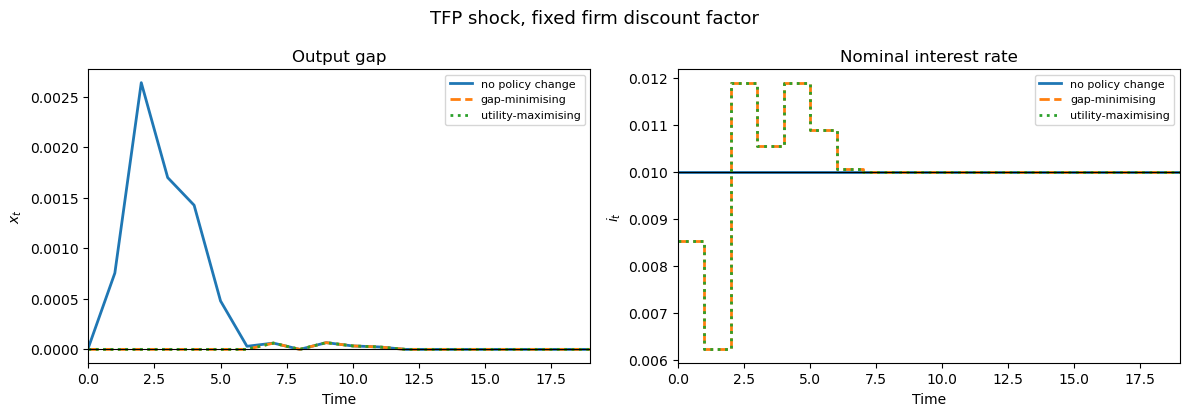

In [8]:
def paths(r, a, demand=None, T=30):
    ip = np.ones(T) * rho
    if r is not None:
        ip[:len(r)] = r
    x, pi, y_nat, r_nat = gap_IS(ip, a, demand)
    return (x, ip), x + y_nat

rA_gap = histA_gap[-1][1]
rA_u = histA_u[-1][1]
baseA, yA_b = paths(None, a_A)
gapA, yA_g = paths(rA_gap, a_A)
utilA, yA_u = paths(rA_u, a_A)

print('A SHOCK summary')
print(f'{"":<26}{"sum x^2":>14}{"utility":>16}')
for lab, (xx, ii), yy in [('no policy change', baseA, yA_b),
                          ('gap-minimising', gapA, yA_g),
                          ('utility-maximising', utilA, yA_u)]:
    print(f'{lab:<26}{np.sum(xx**2):>14.6e}{welfare(yy, a_A):>16.8f}')
print()
print(f'gap-optimal rates     : {np.round(rA_gap, 5)}')
print(f'utility-optimal rates : {np.round(rA_u, 5)}')

compare_figure('TFP shock, fixed firm discount factor', a_A, baseA, gapA, utilA,
               '../semi_endo_fixedbeta_A_shock.png')

## 4. Demand shock

A demand shock enters the natural rate, $r^n_t = \rho - d_t + \gamma\Delta y^n_{t+1}$.

Note what fixing $\beta_f$ does here: with no TFP shock, `tprod` is constant across
periods, so $a_t \equiv 0$ and potential output is flat. Time-to-produce therefore has
**no effect at all** in the demand experiment once the discount factor is fixed — its only
channel in that experiment was the rate feeding into `tprod`. The exogenous-time-to-build
and no-time-to-build cases collapse to the same thing.

In [9]:
a_D = tfp_path(T, shock=False)
print(f'demand-shock TFP path: max |a_t| = {np.max(np.abs(a_D)):.3e}  (flat, as expected)')

demand = np.zeros(T)
demand[0] = 0.01                      # 1 percent demand shock


def obj_gap_D(r, T):
    ip = np.ones(T) * rho; ip[:len(r)] = r
    x, *_ = gap_IS(ip, a_D, demand)
    return float(np.sum(x**2))


def obj_util_D(r, T):
    ip = np.ones(T) * rho; ip[:len(r)] = r
    x, pi, y_nat, r_nat = gap_IS(ip, a_D, demand)
    return -welfare(x + y_nat, a_D)


histD_gap, LD_gap = escalate(obj_gap_D, T, 'DEMAND SHOCK -- gap objective  min sum x^2')
histD_u, LD_u = escalate(obj_util_D, T, 'DEMAND SHOCK -- planner  max utility')

demand-shock TFP path: max |a_t| = 0.000e+00  (flat, as expected)
DEMAND SHOCK -- gap objective  min sum x^2
  L    last i_t  settled       objective   optimal sequence
--------------------------------------------------------------------------------------------
  3    0.010000     True    1.874900e-17   [0.   0.01 0.01]

-> settles at L = 3: back to rho = 0.0100

DEMAND SHOCK -- planner  max utility
  L    last i_t  settled       objective   optimal sequence
--------------------------------------------------------------------------------------------
  3    0.010000     True    3.475438e+01   [0.   0.01 0.01]

-> settles at L = 3: back to rho = 0.0100



DEMAND SHOCK summary
                                 sum x^2         utility
no policy change            2.500000e-05    -34.75443024
gap-minimising              1.874900e-17    -34.75438040
utility-maximising          2.839342e-15    -34.75438040

gap-optimal rates     : [0.   0.01 0.01]
utility-optimal rates : [0.   0.01 0.01]
natural rate r^n[:4]  : [0.   0.01 0.01 0.01]


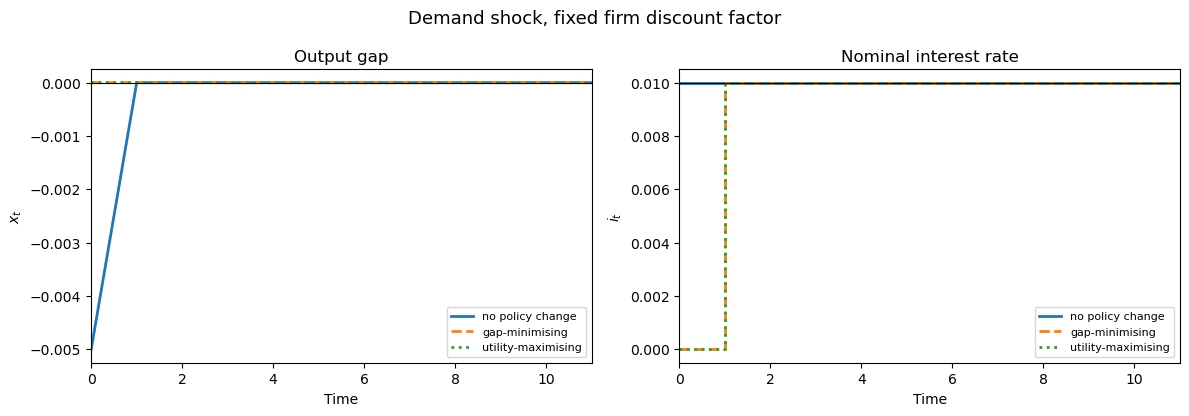

In [10]:
rD_gap = histD_gap[-1][1]
rD_u = histD_u[-1][1]
baseD, yD_b = paths(None, a_D, demand)
gapD, yD_g = paths(rD_gap, a_D, demand)
utilD, yD_u = paths(rD_u, a_D, demand)

print('DEMAND SHOCK summary')
print(f'{"":<26}{"sum x^2":>14}{"utility":>16}')
for lab, (xx, ii), yy in [('no policy change', baseD, yD_b),
                          ('gap-minimising', gapD, yD_g),
                          ('utility-maximising', utilD, yD_u)]:
    print(f'{lab:<26}{np.sum(xx**2):>14.6e}{welfare(yy, a_D):>16.8f}')
print()
print(f'gap-optimal rates     : {np.round(rD_gap, 5)}')
print(f'utility-optimal rates : {np.round(rD_u, 5)}')
print(f'natural rate r^n[:4]  : {np.round(gap_IS(np.ones(T)*rho, a_D, demand)[3][:4], 5)}')

compare_figure('Demand shock, fixed firm discount factor', a_D, baseD, gapD, utilD,
               '../semi_endo_fixedbeta_demand_shock.png', horizon=12)